# Chapter 9 · Importance sampling: interactive demos

Companion to Chapter 9 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/09-importance-sampling.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

Throughout, the test case is $S=K=100$, $T=1$, $r=1\%$, $y=2\%$, $\sigma=20\%$ (call price 7.36429), and
$\log(S_T/S)\sim\mathcal N(\nu T,\sigma^2T)$ with $\nu=r-y-\sigma^2/2$. Importance sampling draws
$\log(S_T/S)$ from $\mathcal N((\nu+\alpha)T,\beta^2\sigma^2T)$ and multiplies the payoff by the weight $L=q/\tilde q$.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from mfe230d import importance as im
from mfe230d.bs import TEST_CASE
from mfe230d.montecarlo import mc_estimate
from mfe230d.variance import strike_to_z, control_variate, plain
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style

use_style()
GREEN, PURPLE = "#1BAF7A", "#6250D6"
P = TEST_CASE
S, T, r, y, SIG = (P[k] for k in ("S", "T", "r", "y", "sigma"))
NU, SD = r - y - 0.5 * SIG**2, SIG * np.sqrt(T)

## 1. The course's experiment: shift and scale the terminal law

Left: the risk-neutral density of $S_T$, the sampling density and (dashed) the zero-variance density
$\propto (S_T-K)^+q$ of Proposition 9.2. Right: the weighted payoff $e^{-rT}(S_T-K)^+L$, whose mean under the
sampling law is the price for every $(\alpha,\beta)$. The title gives the exact variance ratio (plain over
importance sampling) from Proposition 9.3 and a Monte Carlo check with $2^{16}$ samples.

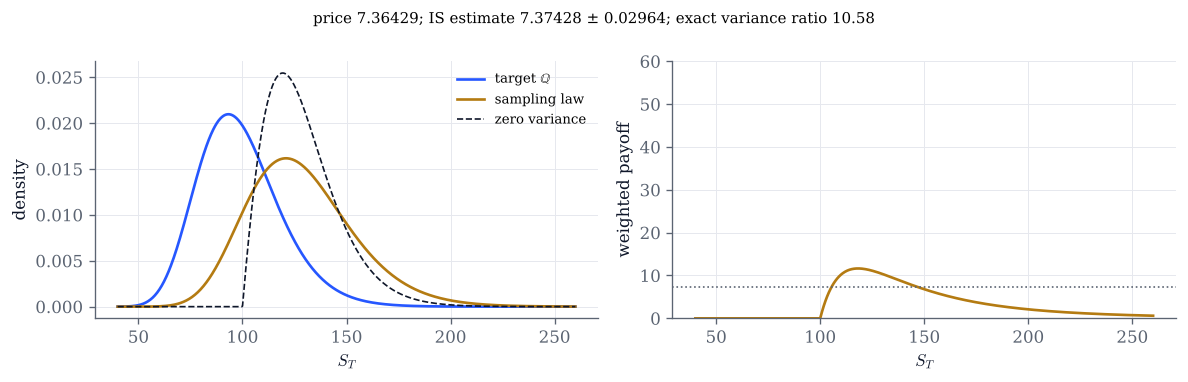

In [2]:
def lognormal_pdf(s, alpha=0.0, beta=1.0):
    x, v = np.log(s / S), (beta * SD) ** 2
    return np.exp(-0.5 * (x - (NU + alpha) * T) ** 2 / v) / (s * np.sqrt(2 * np.pi * v))

def experiment(alpha=0.26, beta=1.0, K=100.0, seed=1):
    s = np.linspace(40, 260, 800)
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.2))
    ax.plot(s, lognormal_pdf(s), color=COBALT, label="target $\\mathbb{Q}$")
    ax.plot(s, lognormal_pdf(s, alpha, beta), color=GOLD, label="sampling law")
    zv = np.maximum(s - K, 0) * lognormal_pdf(s); zv /= np.trapezoid(zv, s)
    ax.plot(s, zv, color=INK, ls="--", lw=1, label="zero variance")
    ax.set(xlabel="$S_T$", ylabel="density"); ax.legend(fontsize=8)
    L = lognormal_pdf(s) / lognormal_pdf(s, alpha, beta)
    bx.plot(s, np.exp(-r * T) * np.maximum(s - K, 0) * L, color=GOLD)
    price, m2 = im.is_moments("call", S, K, T, r, y, SIG, alpha, beta)
    bx.axhline(price, color=GREY, ls=":", lw=1)
    bx.set(xlabel="$S_T$", ylabel="weighted payoff", ylim=(0, max(5 * price, 60 if K <= 110 else 5 * price)))
    vr = im.variance_ratio("call", S, K, T, r, y, SIG, alpha, beta) if np.isfinite(m2) else 0.0
    Y, _, _ = im.sample_terminal_is("call", S, K, T, r, y, SIG, alpha, beta, 2**16, seed=seed)
    e = mc_estimate(Y)
    fig.suptitle(f"price {price:.5f}; IS estimate {e['mean']:.5f} ± {1.96*e['se']:.5f}; "
                 + (f"exact variance ratio {vr:.2f}" if np.isfinite(m2) else "INFINITE variance (beta <= 1/sqrt 2)"),
                 fontsize=9)
    fig.tight_layout(); plt.show()

experiment()

In [3]:
# Explore: find the best alpha at each strike; then lower beta towards 1/sqrt(2) = 0.707 and below.
interact(experiment,
         alpha=FloatSlider(value=0.26, min=-0.2, max=1.0, step=0.01, continuous_update=False, description="α"),
         beta=FloatSlider(value=1.0, min=0.6, max=1.5, step=0.01, continuous_update=False, description="β"),
         K=FloatSlider(value=100.0, min=60.0, max=200.0, step=5.0, continuous_update=False, description="K"),
         seed=IntSlider(value=1, min=0, max=50, continuous_update=False, description="seed"));

## 2. What an infinite variance looks like

For $\beta\le 1/\sqrt2$ the weight has infinite variance (Proposition 9.3) and, for the call, so does the
estimator when $\beta<1/\sqrt2$. The estimate still converges, but the running sample standard deviation
$\hat s_n$ never settles: it creeps up and jumps whenever a rare, huge weight arrives. For
$1/\sqrt2<\beta<\sqrt3/2$ the variance is finite but the fourth moment is not (Remark 9.5), so $\hat s_n$ converges
slowly. Dashed lines: exact standard deviations where they are finite.

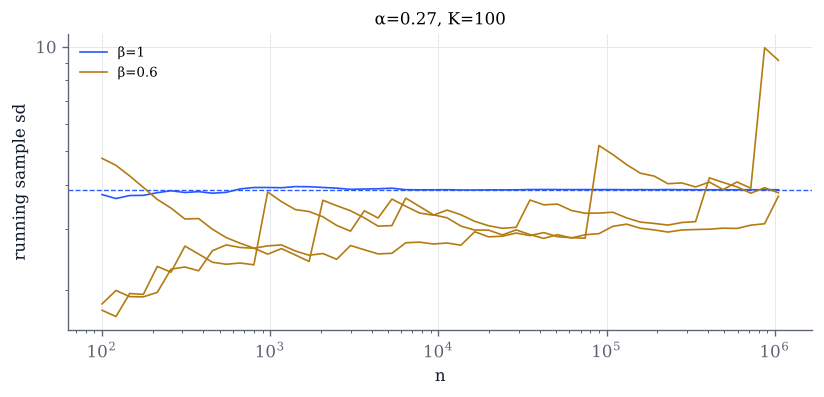

In [4]:
def running_sd(beta=0.6, alpha=0.27, n_log2=20, seeds=3):
    n_max = 2**n_log2
    ns = np.unique(np.round(np.logspace(2, np.log10(n_max), 50)).astype(int))
    fig, ax = plt.subplots(figsize=(8, 3.2))
    for b, col in ((1.0, COBALT), (beta, GOLD)):
        p, m2 = im.is_moments("call", S, 100.0, T, r, y, SIG, alpha, b)
        if np.isfinite(m2):
            ax.axhline(np.sqrt(m2 - p * p), color=col, ls="--", lw=0.8)
        for k in range(seeds if b == beta else 1):
            Y, _, _ = im.sample_terminal_is("call", S, 100.0, T, r, y, SIG, alpha, b, n_max, seed=k + 1)
            c1, c2 = np.cumsum(Y), np.cumsum(Y * Y)
            ax.plot(ns, np.sqrt((c2[ns - 1] - c1[ns - 1] ** 2 / ns) / (ns - 1)), color=col, lw=1,
                    label=f"β={b:g}" if k == 0 else None)
    ax.set(xscale="log", yscale="log", xlabel="n", ylabel="running sample sd", title=f"α={alpha}, K=100")
    ax.yaxis.set_major_formatter(plt.ScalarFormatter()); ax.yaxis.set_minor_formatter(plt.NullFormatter())
    ax.legend(fontsize=8); plt.show()

running_sd()

In [5]:
interact(running_sd,
         beta=FloatSlider(value=0.6, min=0.5, max=1.2, step=0.01, continuous_update=False, description="β"),
         alpha=FloatSlider(value=0.27, min=0.0, max=0.6, step=0.01, continuous_update=False, description="α"),
         n_log2=IntSlider(value=20, min=12, max=22, continuous_update=False, description="log2 n"),
         seeds=IntSlider(value=3, min=1, max=6, continuous_update=False, description="seeds"));

## 3. Deep out of the money: relative error per sample

The relative error per sample, $\sqrt{\mathrm{Var}(Y)}/p$, decides how many samples a given relative precision needs.
Plain Monte Carlo explodes like $e^{d^2/4}$ with $d=-d_-$; the mean shift chosen by Glasserman, Heidelberger and
Shahabuddin (GHS) grows only like $\sqrt d$ (Proposition 9.15). All curves are exact; dots are Monte Carlo.

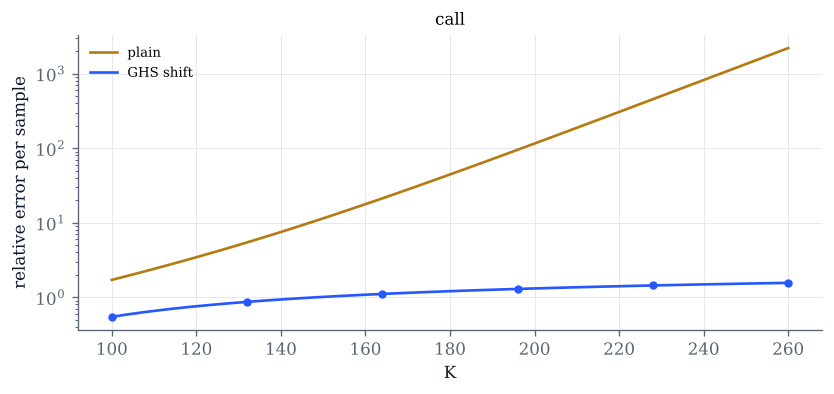

In [6]:
def relative_error(kind="call", K_max=260.0, n=20_000, seed=3):
    Ks = np.linspace(100, K_max, 41)
    d = strike_to_z(Ks, S, T, r, y, SIG)
    def re(k, c):
        p, m2 = im.is_moments(kind, S, k, T, r, y, SIG, c * SD / T)
        return np.sqrt(m2 / p**2 - 1)
    ghs = d if kind == "digital" else np.array([im.ghs_shift_call(dd, SD) for dd in d])
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.plot(Ks, [re(k, 0.0) for k in Ks], color=GOLD, label="plain")
    ax.plot(Ks, [re(k, c) for k, c in zip(Ks, ghs)], color=COBALT, label="GHS shift")
    if kind == "digital":
        ax.plot(Ks, np.sqrt(im.tail_exponential_relative_moment(d) - 1), color=PURPLE, label="exponential sampler")
    for k, c in list(zip(Ks, ghs))[::8]:
        Y, _, _ = im.sample_terminal_is(kind, S, k, T, r, y, SIG, c * SD / T, 1.0, n, seed=seed)
        ax.plot(k, Y.std(ddof=1) / Y.mean(), "o", color=COBALT, ms=4)
    ax.set(yscale="log", xlabel="K", ylabel="relative error per sample", title="digital call" if kind == "digital" else "call")
    ax.legend(fontsize=8); plt.show()

relative_error()

In [7]:
interact(relative_error,
         kind=Dropdown(options=["call", "digital"], value="call", description="payoff"),
         K_max=FloatSlider(value=260.0, min=150.0, max=400.0, step=10.0, continuous_update=False, description="K max"),
         n=IntSlider(value=20_000, min=2_000, max=200_000, step=2_000, continuous_update=False, description="n"),
         seed=IntSlider(value=3, min=0, max=50, continuous_update=False, description="seed"));

## 4. Path space: the GHS drift and cross-entropy for an Asian call

The arithmetic Asian call on 16 fixings is a function of 16 normals. Shifting them to $\mathcal N(\mu,I)$ is a
Girsanov change of drift (Theorem 9.8). The GHS drift maximises payoff times density; the cross-entropy method
(Proposition 9.16) climbs to the strike through quantile levels and averages the weighted normals. Left: the two
drifts. Right: the cross-entropy levels and $|v_t|$ per iteration.

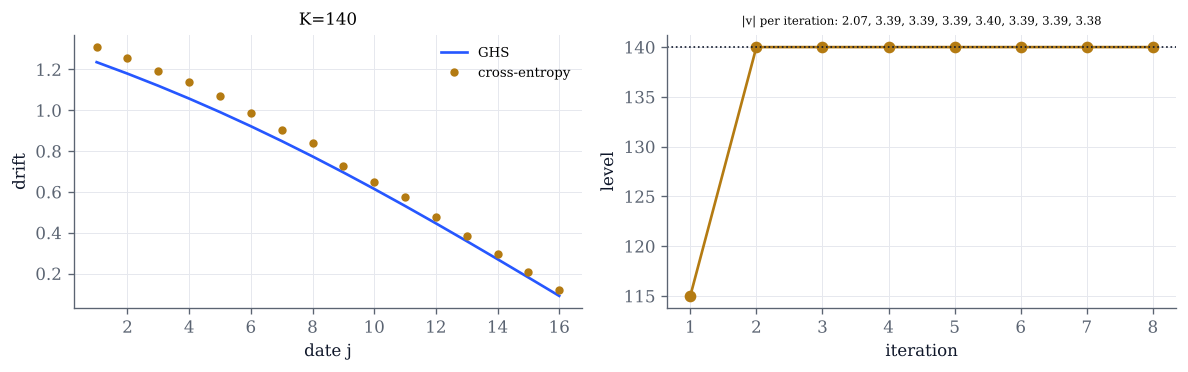

In [8]:
def asian_drifts(K=140.0, rho=0.1, n_per_iter=10_000, n_iter=8, seed=1):
    m = 16
    mu = im.asian_ghs_drift(S, K, T, r, y, SIG, m)
    score = lambda Z: im.asian_dates_prices(Z, S, T, r, y, SIG).mean(axis=1)
    hist, levels = im.cross_entropy_drift(score, K, m, n=n_per_iter, n_iter=n_iter, rho=rho, seed=seed)
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.2))
    j = np.arange(1, m + 1)
    ax.plot(j, mu, color=COBALT, label="GHS")
    ax.plot(j, hist[-1], "o", color=GOLD, ms=4, label="cross-entropy")
    ax.set(xlabel="date j", ylabel="drift", title=f"K={K:.0f}"); ax.legend(fontsize=8)
    it = np.arange(1, n_iter + 1)
    bx.plot(it, levels, "o-", color=GOLD, label="level γ_t")
    bx.axhline(K, color=INK, ls=":", lw=1)
    bx.set(xlabel="iteration", ylabel="level", title=f"|v| per iteration: " + ", ".join(f"{np.linalg.norm(v):.2f}" for v in hist[1:]))
    bx.title.set_fontsize(7)
    plt.tight_layout(); plt.show()

asian_drifts()

In [9]:
interact(asian_drifts,
         K=FloatSlider(value=140.0, min=100.0, max=180.0, step=5.0, continuous_update=False, description="K"),
         rho=FloatSlider(value=0.1, min=0.01, max=0.5, step=0.01, continuous_update=False, description="ρ"),
         n_per_iter=IntSlider(value=10_000, min=500, max=50_000, step=500, continuous_update=False, description="n/iter"),
         n_iter=IntSlider(value=8, min=2, max=15, continuous_update=False, description="iterations"),
         seed=IntSlider(value=1, min=0, max=50, continuous_update=False, description="seed"));

## 5. Effective sample size in growing dimension

$\mathrm{ESS}=(\sum L_i)^2/\sum L_i^2$ tends to $n/\tilde{\mathbb E}[L^2]$ (Proposition 9.17). For a mean shift it depends
only on $|\mu|^2$: a shift of fixed total size spread over many dates is harmless, a fixed shift per date is not,
and a rescaling of every date degenerates geometrically. Lines exact, dots sampled.

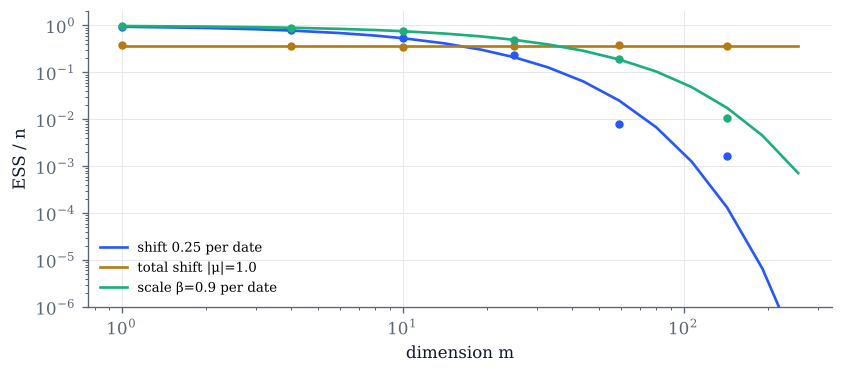

In [10]:
def ess(c=0.25, total=1.0, beta=0.9, n=10_000, seed=9):
    dims = np.unique(np.round(np.logspace(0, np.log10(256), 20)).astype(int))
    rng = np.random.default_rng(seed)
    fig, ax = plt.subplots(figsize=(8, 3.2))
    cases = ((COBALT, f"shift {c} per date", lambda m: np.full(m, c), 1.0),
             (GOLD, f"total shift |μ|={total}", lambda m: np.full(m, total / np.sqrt(m)), 1.0),
             (GREEN, f"scale β={beta} per date", lambda m: np.zeros(m), beta))
    for col, name, drift, b in cases:
        th = [np.exp(-np.sum(drift(m) ** 2)) if b == 1 else (np.sqrt(max(2 * b * b - 1, 0)) / b**2) ** m for m in dims]
        ax.plot(dims, th, color=col, label=name)
        for m in dims[::3]:
            x = drift(m) + b * rng.standard_normal((n, m))
            lw = np.sum(im.gaussian_log_lr(x, 0.0, 1.0, drift(m), b), axis=1)
            w = np.exp(lw - lw.max())
            ax.plot(m, im.effective_sample_size(w) / n, "o", color=col, ms=4)
    ax.set(xscale="log", yscale="log", ylim=(1e-6, 2), xlabel="dimension m", ylabel="ESS / n")
    ax.legend(fontsize=8); plt.show()

ess()

In [11]:
interact(ess,
         c=FloatSlider(value=0.25, min=0.0, max=1.0, step=0.05, continuous_update=False, description="c"),
         total=FloatSlider(value=1.0, min=0.0, max=3.0, step=0.1, continuous_update=False, description="|μ|"),
         beta=FloatSlider(value=0.9, min=0.75, max=1.5, step=0.01, continuous_update=False, description="β"),
         n=IntSlider(value=10_000, min=1_000, max=100_000, step=1_000, continuous_update=False, description="n"),
         seed=IntSlider(value=9, min=0, max=50, continuous_update=False, description="seed"));

## 6. Laboratory: importance sampling and a control variate together

For the Asian call, the geometric Asian call (exact price) is a control variate. Under importance sampling the
control is weighted too, $C L$, and keeps its known mean (Proposition 9.18). The bars show the standard errors of
the four estimators at equal $n$; the control dominates near the money, importance sampling in the tail.

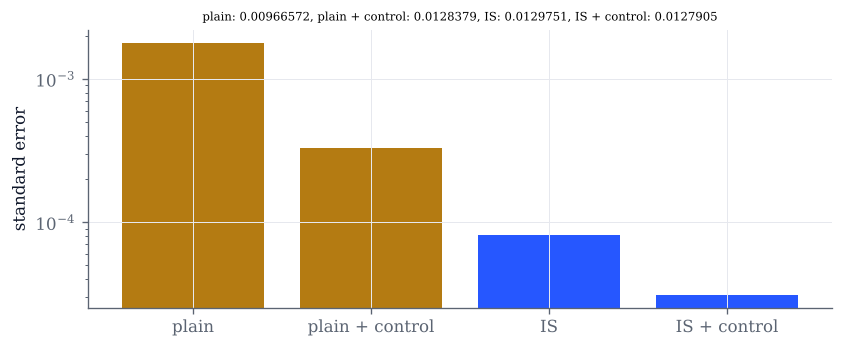

In [12]:
def laboratory(K=140.0, n_log2=15, seed=2026):
    m, n = 16, 2**n_log2
    geo = im.geometric_asian_call(S, K, T, r, y, SIG, m)
    mu = im.asian_ghs_drift(S, K, T, r, y, SIG, m)
    ss = np.random.SeedSequence(seed).spawn(2)
    res = {}
    for name, drift, sd in (("plain", np.zeros(m), ss[0]), ("IS", mu, ss[1])):
        Y, C, L = im.asian_is_samples(S, K, T, r, y, SIG, m, drift, n, seed=sd)
        res[name] = plain(Y)
        res[name + " + control"] = control_variate(Y, C, geo, beta="estimated")
    names = ["plain", "plain + control", "IS", "IS + control"]
    fig, ax = plt.subplots(figsize=(8, 3.0))
    ax.bar(names, [res[k]["se"] for k in names], color=[GOLD, GOLD, COBALT, COBALT])
    ax.set(yscale="log", ylabel="standard error", title=", ".join(f"{k}: {res[k]['mean']:.6g}" for k in names))
    ax.title.set_fontsize(7)
    plt.show()

laboratory()

In [13]:
interact(laboratory,
         K=FloatSlider(value=140.0, min=90.0, max=180.0, step=5.0, continuous_update=False, description="K"),
         n_log2=IntSlider(value=15, min=10, max=19, continuous_update=False, description="log2 n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## Things to try

- In section 1, set $K=60$ and find the best $\alpha$ by hand. Then compare with $\sigma^2=0.04$: what is special about
  sampling under the share measure?
- In section 1, keep $\alpha=0.27$ and lower $\beta$ slowly from 1 to 0.70. The exact variance ratio keeps improving
  until it suddenly becomes infinite. Does the Monte Carlo estimate in the title warn you?
- In section 2, try $\beta=0.72$ and $\beta=0.80$, both with finite variance. Which running standard deviation looks
  more trustworthy, and why?
- In section 4, make $\rho$ very small with few paths per iteration. What happens to the cross-entropy drift?
- In section 6, find the strike at which importance sampling alone starts to beat the control variate alone.